In [2]:
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays, JSON
using Colors
using CSV
using DataFrames
using MLJ
using Dates
using JuMP, Ipopt
using LinearAlgebra

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

Best: (rmse = 0.11574447996733331, λ = 0.02, γ = 3.5)
Final validation RMSE = 0.1157
Test RMSE = 0.1172


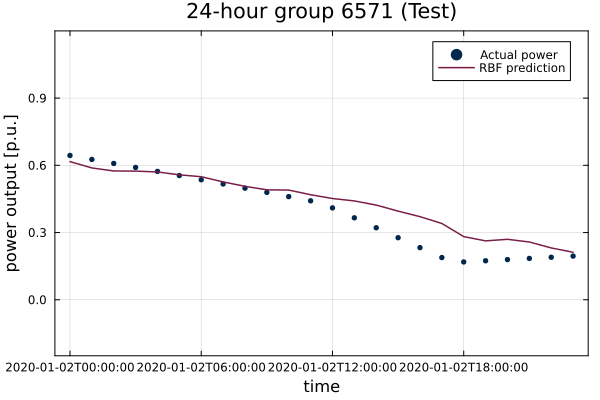

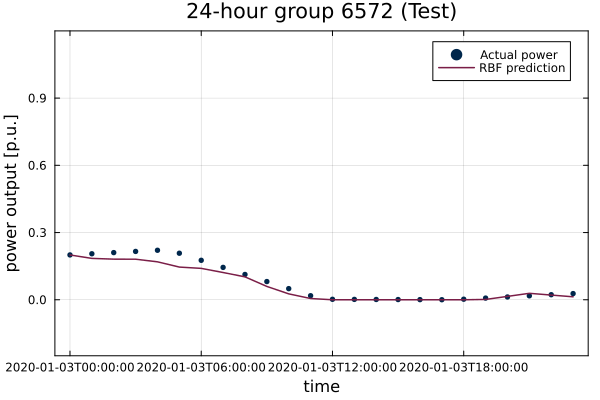

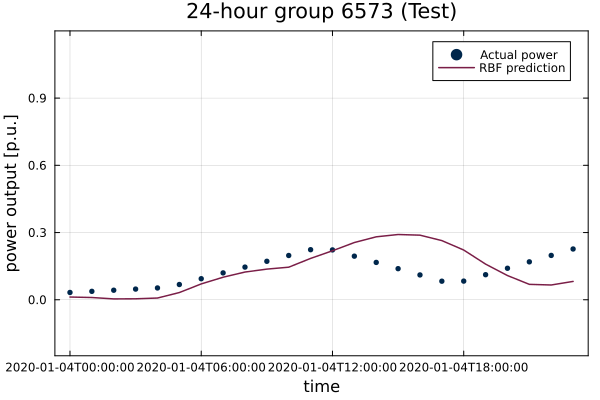

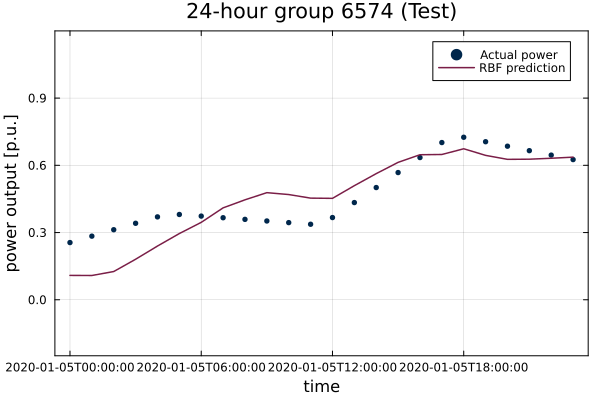

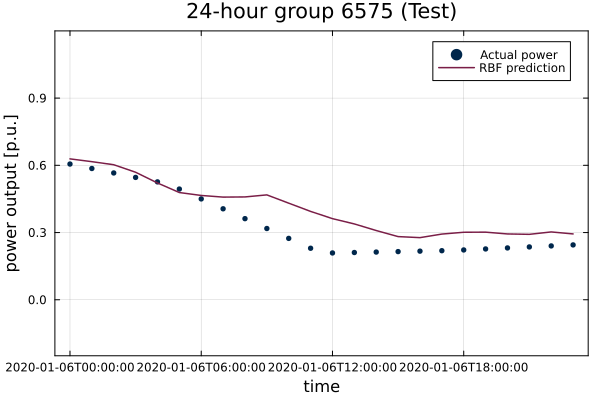

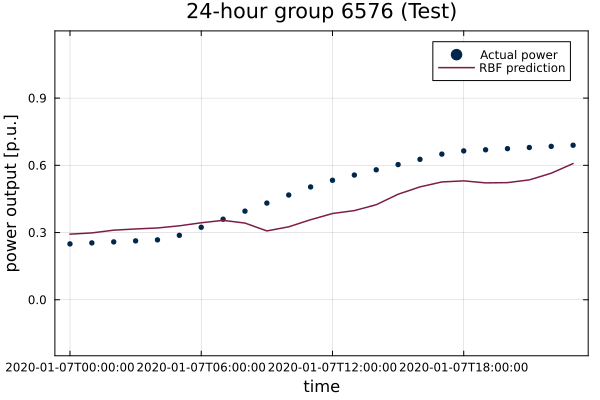

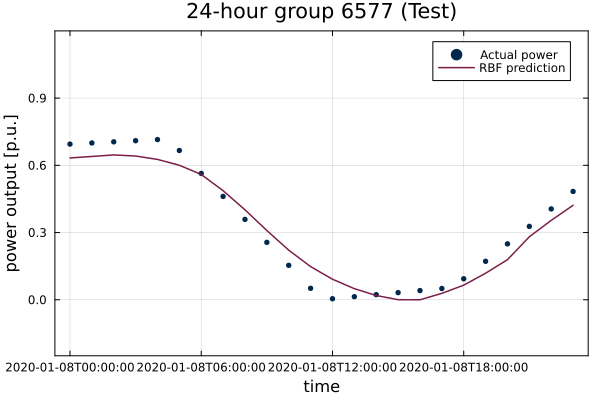

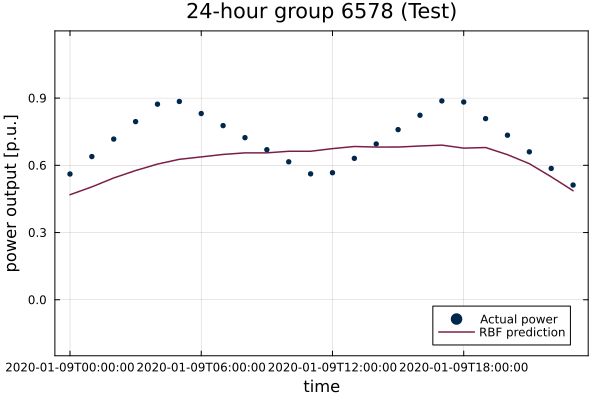

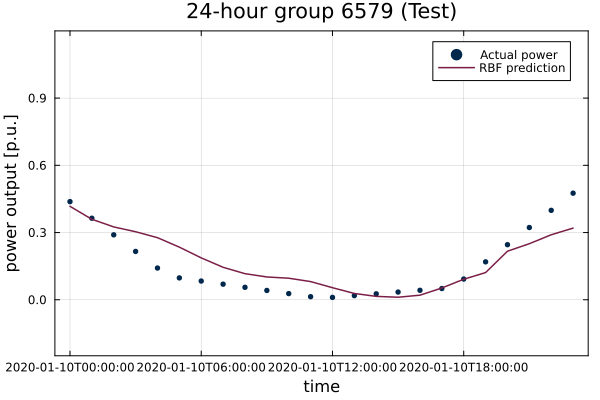

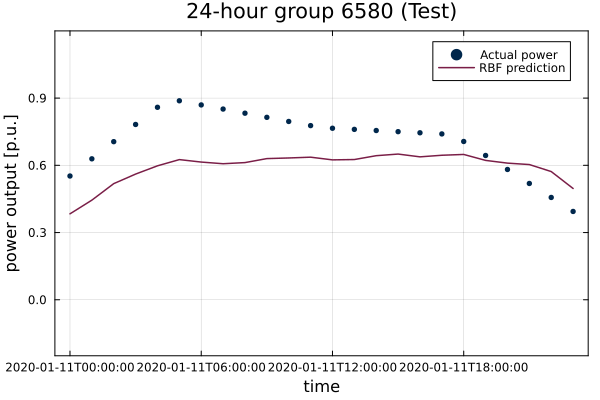

In [8]:
# Load all four locations
dfs = [CSV.read("location$i.csv", DataFrame; types = Dict(:Time => String)) for i in 1:4]

# Convert timestamps and assign location IDs
for (i, data) in enumerate(dfs)
    data.Time = DateTime.(data.Time, dateformat"yyyy-mm-dd HH:MM:SS")
    data.LocationID = fill(i, nrow(data))
end

# Combine all locations and sort by location and time
df = vcat(dfs...)
sort!(df, [:LocationID, :Time])

m     = nrow(df)
times = df.Time
t     = Float64.(df.Power)

# Normalize weather features across all four locations
x10m  = Float64.(df.windspeed_10m) ./ maximum(df.windspeed_10m)
x100m = Float64.(df.windspeed_100m) ./ maximum(df.windspeed_100m)
x10g  = Float64.(df.windgusts_10m) ./ maximum(df.windgusts_10m)

# 24-hour groups
hours_per_group = 24
num_groups = div(m, hours_per_group)

m_used = num_groups * hours_per_group

times = times[1:m_used]
t     = t[1:m_used]
x10m  = x10m[1:m_used]
x100m = x100m[1:m_used]
x10g  = x10g[1:m_used]

location_ids = df.LocationID[1:m_used]

train, val, test = partition(1:num_groups, 0.8, 0.1;shuffle = false,rng = 120)

c = collect(0.0:0.05:1)
num_centers = length(c)

function rbf_features(xs, γ)

    Φ = zeros(length(xs), num_centers)
    for i in eachindex(xs), j in 1:num_centers
        Φ[i, j] = exp(-(γ * abs(xs[i] - c[j]))^2)
    end
    
    return Φ
end

weather_design_matrix(x1, x2, x3, γ) = hcat(rbf_features(x1, γ), rbf_features(x2, γ), rbf_features(x3, γ))

grouped_design_matrix(x1, x2, x3, lag_power, γ) = hcat(weather_design_matrix(x1, x2, x3, γ), lag_power)
Y_all = t

group_to_indices(groups, hours_per_group) = vcat([((g - 1) * hours_per_group + 1):(g * hours_per_group) for g in groups]...)

train_idx = group_to_indices(train, hours_per_group)
val_idx   = group_to_indices(val, hours_per_group)
test_idx  = group_to_indices(test, hours_per_group)

train_idx_fit = filter(i -> i > 1, train_idx)

function train_rbf(Φ, t;α = 0.02,n_epochs = 20,λ = 0.001,reg_type = :l2,seed = 128)

    rng = MersenneTwister(seed)
    ntrain = size(Φ, 1)
    nfeat  = size(Φ, 2)
    w_0 = 0.0
    w   = zeros(nfeat)

    for epoch in 1:n_epochs
        for i in shuffle(rng, 1:ntrain)

            ϕi = @view Φ[i, :]
            err = (w_0 + dot(ϕi, w)) - t[i]
            w_0 -= α * err
            w   .-= α * err .* ϕi

            if reg_type == :l2
                w .-= α * λ .* w

            elseif reg_type == :l1
                w .= sign.(w) .* max.(0, abs.(w) .- α * λ)

            end
        end
    end

    return w_0, w
end

predict_rbf(Φ, w_0, w) = w_0 .+ Φ * w

rmse(y_pred, y_actual) = sqrt(mean((y_pred .- y_actual).^2))


# ---------- Recursive prediction ----------

function predict_recursive(Φ_weather, indices, initial_lag, w_0, w)

    n = length(indices)
    predictions = zeros(n)
    previous_power = initial_lag

    for j in 1:n

        # Weather features for the current hour
        ϕ_weather = @view Φ_weather[indices[j], :]

        # Append raw previous-hour power
        ϕ = vcat(collect(ϕ_weather), previous_power)

        # Make current prediction
        prediction = w_0 + dot(ϕ, w)

        # Keep prediction within normalized power range
        prediction = clamp(prediction, 0.0, 1.0)

        predictions[j] = prediction

        # Feed prediction into the next hourly observation
        previous_power = prediction

    end

    return predictions
end


# ---------- Hyperparameter search ----------

λ_grid = [9e-3, 1e-2, 2e-2]
γ_grid = [1.5, 2.5, 3.5, 4.5, 5]

best = (rmse = Inf, λ = NaN, γ = NaN)

# Initial validation lag:
# Actual power from the final training observation
initial_val_lag = t[first(val_idx) - 1]

for γ in γ_grid, λ in λ_grid

    Φ_weather = weather_design_matrix(x10m, x100m, x10g, γ)
    lag_train = t[train_idx_fit .- 1]
    
    Φ_train = grouped_design_matrix(x10m[train_idx_fit],x100m[train_idx_fit],x10g[train_idx_fit],lag_train,γ)
    Y_train = Y_all[train_idx_fit]

    w_0, w = train_rbf(Φ_train, Y_train; λ = λ)

    Y_val_pred = predict_recursive(Φ_weather, val_idx, initial_val_lag, w_0, w)
    Y_val = Y_all[val_idx]

    score = rmse(Y_val_pred, Y_val)

    if isfinite(score) && score < best.rmse
        global best = (rmse = score,λ = λ,γ = γ)
    end
end

println("Best: ", best)

# ---------- Final fit and test evaluation ----------

γ, λ = best.γ, best.λ

Φ_weather = weather_design_matrix(x10m, x100m, x10g, γ)

# Training lag uses actual previous-hour measurements
lag_train = t[train_idx_fit .- 1]

Φ_train = grouped_design_matrix(x10m[train_idx_fit],x100m[train_idx_fit],x10g[train_idx_fit],lag_train,γ)
Y_train = Y_all[train_idx_fit]

# Train final model
w_0, w = train_rbf(Φ_train, Y_train; λ = λ)

# ---------- Validation predictions ----------

Y_val_pred = predict_recursive(Φ_weather,val_idx,initial_val_lag,w_0,w)
Y_val = Y_all[val_idx]
val_rmse = rmse(Y_val_pred, Y_val)

println("Final validation RMSE = ", round(val_rmse, digits = 4))


# ---------- Test predictions ----------

# Continue recursively from the final validation prediction
initial_test_lag = t[first(test_idx) - 1]

Y_test_pred = predict_recursive(Φ_weather, test_idx, initial_test_lag, w_0, w)
Y_test = Y_all[test_idx]
test_rmse = rmse(Y_test_pred, Y_test)

println("Test RMSE = ", round(test_rmse, digits = 4))


# ---------- Predictions for every hourly observation ----------

Y_pred = fill(NaN, m_used)

# Training predictions use actual previous-hour measurements
Φ_train_all = grouped_design_matrix(x10m[train_idx_fit],x100m[train_idx_fit],x10g[train_idx_fit],t[train_idx_fit .- 1],γ)

Y_pred[train_idx_fit] .= clamp.(predict_rbf(Φ_train_all, w_0, w),0.0,1.0)
# Validation predictions
Y_pred[val_idx] .= Y_val_pred
# Test predictions
Y_pred[test_idx] .= Y_test_pred

# ---------- Plot each 24-hour group ----------

for group in test[1:min(10, length(test))]

    idx = ((group - 1) * hours_per_group + 1):(group * hours_per_group)

    plo = scatter(times[idx], Y_all[idx], c = blue, label = "Actual power", ms = 3, markerstrokewidth = 0, frame = :box, xlabel = "time", ylabel = "power output [p.u.]", title = "24-hour group $group (Test)")
    plot!(plo, times[idx], Y_pred[idx], lw = 1.5, c = purple, label = "RBF prediction")
    plot!(plo, ylims = (-0.25, 1.2))

    display(plo)
end
